<a href="https://colab.research.google.com/github/bharatsharma2222/stats_practicals/blob/main/Practical10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")

**Load Wine Dataset**

In [ ]:
# Load dataset
wine = load_wine()

# Create DataFrame
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Add output class/target
df["target"] = wine.target

# Display first 5 rows
print("First five rows:")
print(df.head())

# Display dataset information
print("\nDataset shape:", df.shape)
print("\nClass names:", wine.target_names)
print("\nMissing values:")
print(df.isnull().sum())

First five rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  tar

In [ ]:
# Basic statistical summary
print(df.describe())

          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572359   
min         0.9

**Boxplot by output labels/classes**

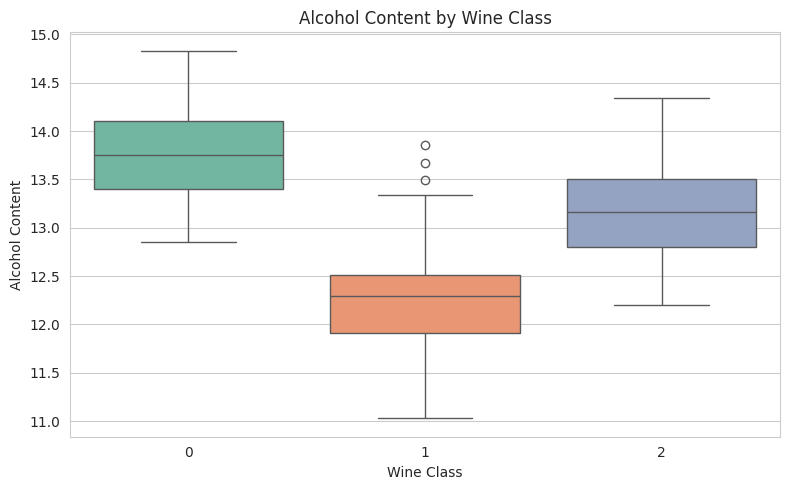

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="target",
    y="alcohol",
    hue="target",
    palette="Set2",
    legend=False
)

plt.title("Alcohol Content by Wine Class")
plt.xlabel("Wine Class")
plt.ylabel("Alcohol Content")
plt.tight_layout()
plt.show()

**The boxplot shows the distribution of alcohol content across the three wine classes (0, 1, and 2). Class 0 has the highest median alcohol content, followed by Class 2, while Class 1 has the lowest. A few outliers are visible in Class 1, indicating some unusually high alcohol values. Therefore, alcohol content can be a useful feature for distinguishing between different wine classes.**

**Scatterplot using two variables**

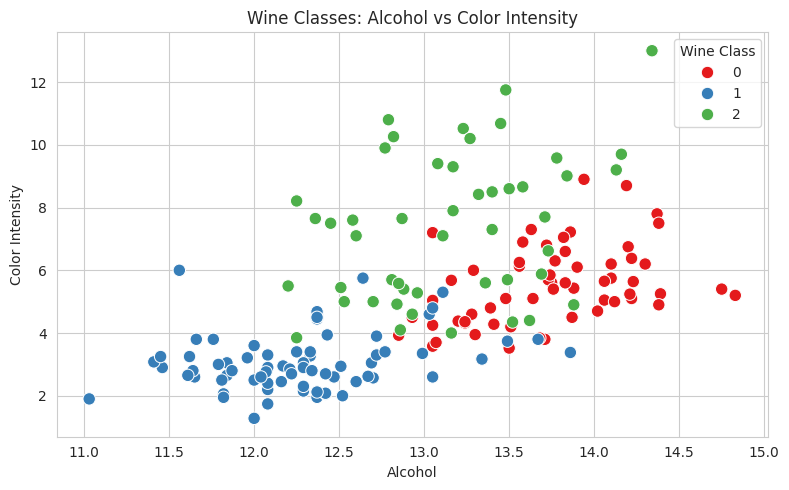

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="alcohol",
    y="color_intensity",
    hue="target",
    palette="Set1",
    s=80
)

plt.title("Wine Classes: Alcohol vs Color Intensity")
plt.xlabel("Alcohol")
plt.ylabel("Color Intensity")
plt.legend(title="Wine Class")
plt.tight_layout()
plt.show()

**The scatter plot shows the relationship between alcohol content and color intensity across the three wine classes. Class 0 (red) generally has higher alcohol content and moderate color intensity, while Class 1 (blue) has lower color intensity and relatively lower alcohol content. Class 2 (green) generally exhibits higher color intensity. Therefore, alcohol content and color intensity are useful features for distinguishing between the three wine classes, although some overlap exists.**

**Plot the covariance matrix**

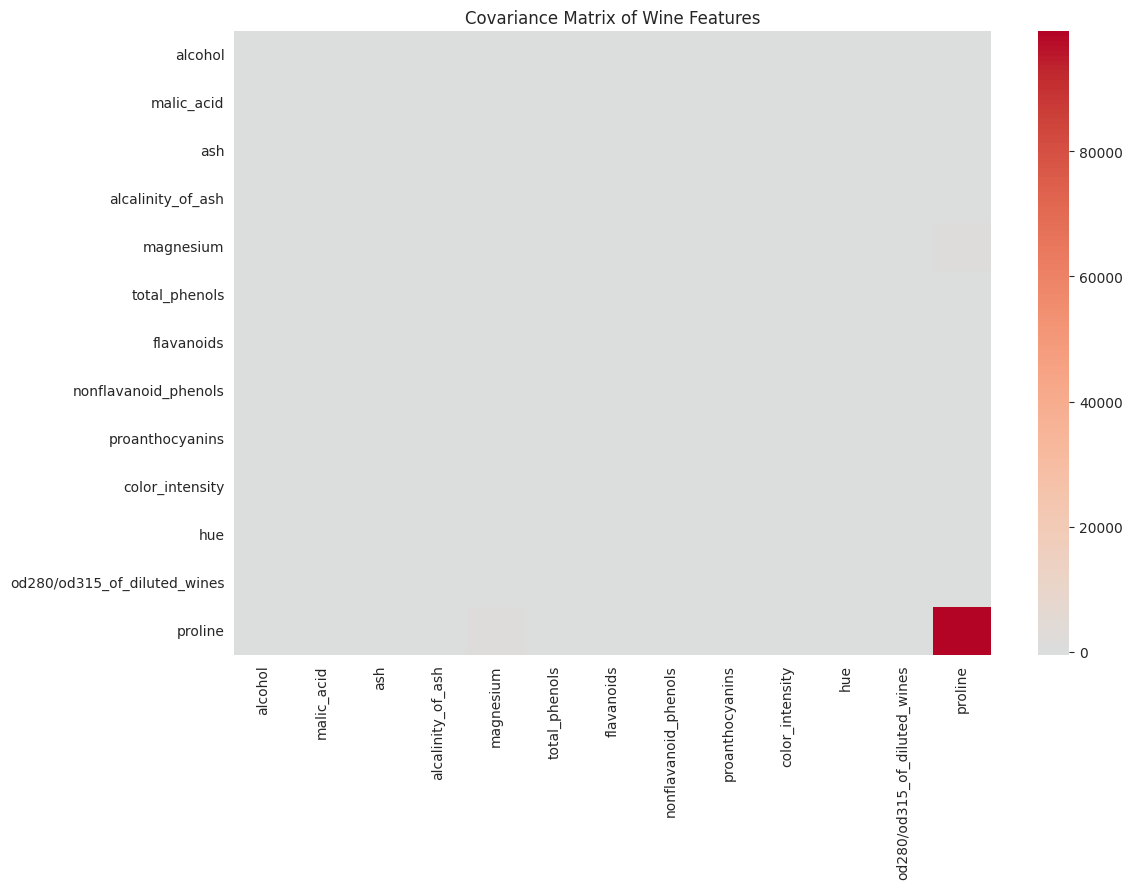

In [ ]:
# Select numerical features only
X = df.drop(columns=["target"])

# Calculate covariance matrix
cov_matrix = X.cov()

# Plot heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    cov_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Covariance Matrix of Wine Features")
plt.tight_layout()
plt.show()

**The covariance matrix heatmap shows the covariance between different features of the Wine dataset. The feature proline has a much larger variance than the other features, which makes the color scale dominated by its value. As a result, differences between the remaining features are difficult to observe. Feature scaling or using a correlation matrix can make the relationships easier to compare.**

**Data scaling using StandardScaler**

In [ ]:
# Separate input features and output labels
X = df.drop(columns=["target"])
y = df["target"]

# Apply standard scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert scaled data back to DataFrame
scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("First five rows after scaling:")
print(scaled_df.head())

print("\nScaled feature means:")
print(scaled_df.mean().round(2))

print("\nScaled feature standard deviations:")
print(scaled_df.std().round(2))

First five rows after scaling:
    alcohol  malic_acid       ash  alcalinity_of_ash  magnesium  \
0  1.518613   -0.562250  0.232053          -1.169593   1.913905   
1  0.246290   -0.499413 -0.827996          -2.490847   0.018145   
2  0.196879    0.021231  1.109334          -0.268738   0.088358   
3  1.691550   -0.346811  0.487926          -0.809251   0.930918   
4  0.295700    0.227694  1.840403           0.451946   1.281985   

   total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
0       0.808997    1.034819             -0.659563         1.224884   
1       0.568648    0.733629             -0.820719        -0.544721   
2       0.808997    1.215533             -0.498407         2.135968   
3       2.491446    1.466525             -0.981875         1.032155   
4       0.808997    0.663351              0.226796         0.401404   

   color_intensity       hue  od280/od315_of_diluted_wines   proline  
0         0.251717  0.362177                      1.847920  1.013009

**StandardScaler was used to normalize the Wine dataset's 13 input features so that each feature has a mean approximately equal to zero and a standard deviation approximately equal to one. This prevents features with larger numerical ranges, such as proline, from dominating distance-based algorithms and PCA. The scaled data is now ready for PCA and other machine-learning algorithms.**

**PCA — better class separation using principal components**

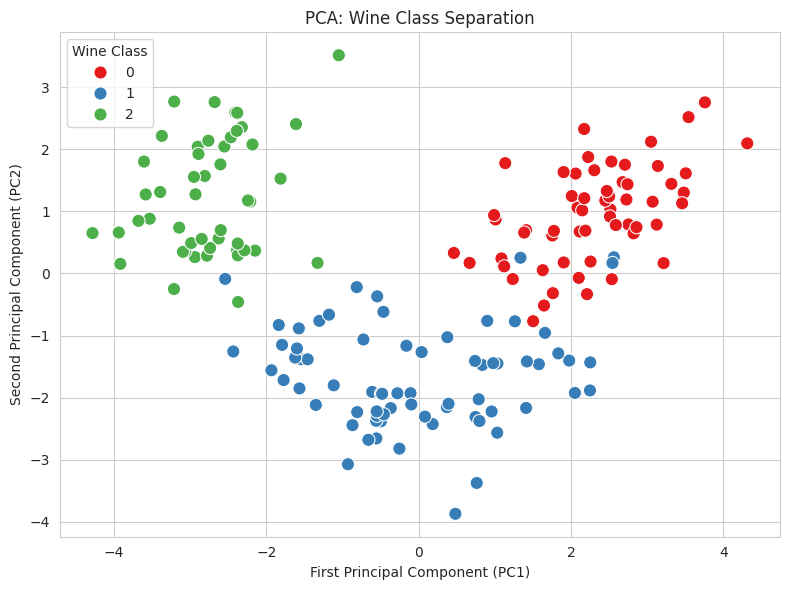

Explained variance ratio: [0.362  0.1921]
Total variance explained by two components: 55.41 %


In [ ]:
# Apply PCA to scaled data
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create DataFrame for plotting
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["target"] = y.values

# Plot PCA result
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="target",
    palette="Set1",
    s=90
)

plt.title("PCA: Wine Class Separation")
plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.legend(title="Wine Class")
plt.tight_layout()
plt.show()

# Explained variance
print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_.round(4)
)

print(
    "Total variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

**PCA was successfully applied to the scaled Wine dataset to reduce its 13 features to 2 principal components (PC1 and PC2). The first component explains 36.2% of the variance, while the second explains 19.21%. Together, they explain 55.41% of the total variance.
The scatter plot shows that the three wine classes are reasonably well separated, with some overlap between classes. Therefore, PCA helps visualize the differences between wine classes in two dimensions while reducing the complexity of the original dataset.**